In [1]:
import pandas as pd
import numpy as np
import joblib

# PD model trained and saved in notebook 02
pd_model = joblib.load('../pd_model_xgb.pkl')

df = pd.read_csv('../data/accepted_2007_to_2018Q4.csv.gz', low_memory=False)
cols = ['funded_amnt', 'term', 'int_rate', 'grade', 'emp_length',
        'home_ownership', 'annual_inc', 'purpose', 'dti', 'loan_status']
df = df[cols]
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()

# Prepare the features (same process as in notebooks 02 and 04)
features = ['funded_amnt', 'term', 'int_rate', 'grade', 'emp_length',
            'home_ownership', 'annual_inc', 'purpose', 'dti']
X_full = df[features].copy().rename(columns={'funded_amnt': 'loan_amnt'})
X_full['term'] = X_full['term'].str.extract(r'(\d+)').astype(float)

emp_map = {'< 1 year': 0, '1 year': 1, '2 years': 2, '3 years': 3, '4 years': 4,
           '5 years': 5, '6 years': 6, '7 years': 7, '8 years': 8, '9 years': 9, '10+ years': 10}
X_full['emp_length'] = X_full['emp_length'].map(emp_map)
grade_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
X_full['grade'] = X_full['grade'].map(grade_map)
X_full = pd.get_dummies(X_full, columns=['home_ownership', 'purpose'], drop_first=True)
X_full['emp_length'] = X_full['emp_length'].fillna(X_full['emp_length'].median())
X_full['dti'] = X_full['dti'].fillna(X_full['dti'].median())

# PD, LGD, EAD (same as in notebook 04)
df['PD'] = pd_model.predict_proba(X_full)[:, 1]
lgd_dict = {'A': 0.403, 'B': 0.395, 'C': 0.407, 'D': 0.408, 'E': 0.401, 'F': 0.404, 'G': 0.435}
df['LGD'] = df['grade'].map(lgd_dict)
df['EAD'] = df['funded_amnt']

el_baseline = (df['PD'] * df['LGD'] * df['EAD']).sum()
print(f"Baseline expected loss (no stress): ${el_baseline:,.2f}")

Baseline expected loss (no stress): $1,687,783,507.57


In [2]:
import matplotlib.pyplot as plt

np.random.seed(42)  # fixed seed so the results are reproducible
n_simulations = 10000

# beta: sensitivity of expected loss to each percentage point of unemployment increase.
# Assumed value (15%), not estimated from data. A bank would calibrate it on its own history.
beta = 0.15

# Simulate 10,000 unemployment shocks, in percentage points.
# Mean 0 (no change on average) and a standard deviation of 2 points (also an assumption)
unemployment_shock = np.random.normal(loc=0, scale=2, size=n_simulations)

# In each scenario the expected loss is scaled by (1 + beta * shock).
# Simplification: the same multiplier is applied to the whole portfolio.
el_simulated = el_baseline * (1 + beta * unemployment_shock)

# Expected loss can't be negative
el_simulated = np.clip(el_simulated, a_min=0, a_max=None)

print(f"Baseline expected loss: ${el_baseline:,.0f}")
print(f"Average simulated expected loss: ${el_simulated.mean():,.0f}")
print(f"95th percentile (adverse scenario): ${np.percentile(el_simulated, 95):,.0f}")
print(f"99th percentile (severe scenario): ${np.percentile(el_simulated, 99):,.0f}")

Baseline expected loss: $1,687,783,508
Average simulated expected loss: $1,686,788,830
95th percentile (adverse scenario): $2,519,544,257
99th percentile (severe scenario): $2,864,926,530


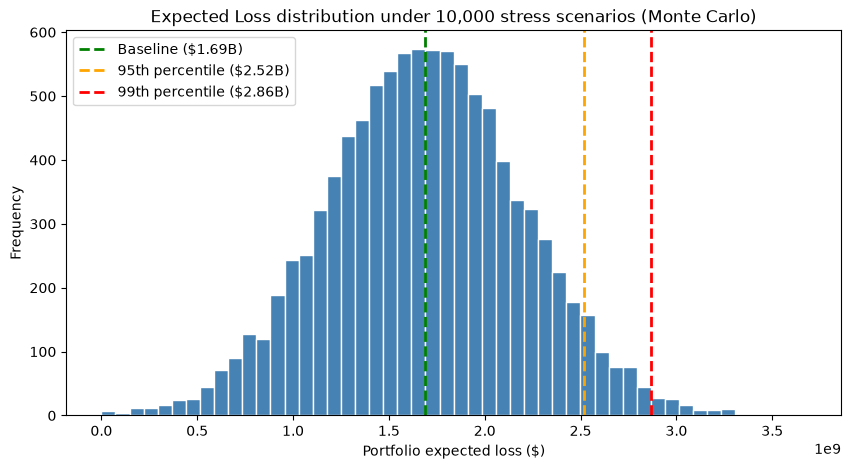

In [3]:
plt.figure(figsize=(10,5))
plt.hist(el_simulated, bins=50, color='steelblue', edgecolor='white')
plt.axvline(el_baseline, color='green', linestyle='--', linewidth=2, label=f'Baseline (${el_baseline/1e9:.2f}B)')
plt.axvline(np.percentile(el_simulated, 95), color='orange', linestyle='--', linewidth=2, label=f'95th percentile (${np.percentile(el_simulated,95)/1e9:.2f}B)')
plt.axvline(np.percentile(el_simulated, 99), color='red', linestyle='--', linewidth=2, label=f'99th percentile (${np.percentile(el_simulated,99)/1e9:.2f}B)')
plt.title('Expected Loss distribution under 10,000 stress scenarios (Monte Carlo)')
plt.xlabel('Portfolio expected loss ($)')
plt.ylabel('Frequency')
plt.legend()
plt.show()